In [1]:
!pip install -q xgboost lightgbm catboost


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import GradientBoostingClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving Phishing_Email.csv to Phishing_Email.csv


In [4]:
df = pd.read_csv("Phishing_Email.csv")

print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()

Dataset dimensions: (18650, 3)

Column names:
['Unnamed: 0', 'Email Text', 'Email Type']

Missing values:
Unnamed: 0     0
Email Text    16
Email Type     0
dtype: int64

Duplicate rows: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18650 entries, 0 to 18649
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  18650 non-null  int64 
 1   Email Text  18634 non-null  object
 2   Email Type  18650 non-null  object
dtypes: int64(1), object(2)
memory usage: 437.2+ KB


In [5]:
df_clean = df[["Email Text", "Email Type"]].copy()

df_clean = df_clean.dropna()

df_clean["Email Text"] = (
    df_clean["Email Text"].str.strip()
)

df_clean = df_clean[df_clean["Email Text"] != ""]

print("Duplicate email texts:",
      df_clean.duplicated(subset=["Email Text"]).sum())

conflicts = df_clean.groupby("Email Text")["Email Type"].nunique()
conflicts = conflicts[conflicts > 1].index

print("Conflicting email texts:", len(conflicts))

df_clean = df_clean[~df_clean["Email Text"].isin(conflicts)]

df_clean = df_clean.drop_duplicates(
    subset=["Email Text"]
).reset_index(drop=True)

print("\nOriginal dataset:", len(df))
print("Cleaned dataset:", len(df_clean))
print("Removed records:", len(df) - len(df_clean))

print("\nEmail classification distribution:")
print(df_clean["Email Type"].value_counts())

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

Duplicate email texts: 1109
Conflicting email texts: 1

Original dataset: 18650
Cleaned dataset: 17521
Removed records: 1129

Email classification distribution:
Email Type
Safe Email        10978
Phishing Email     6543
Name: count, dtype: int64

Remaining missing values:
Email Text    0
Email Type    0
dtype: int64


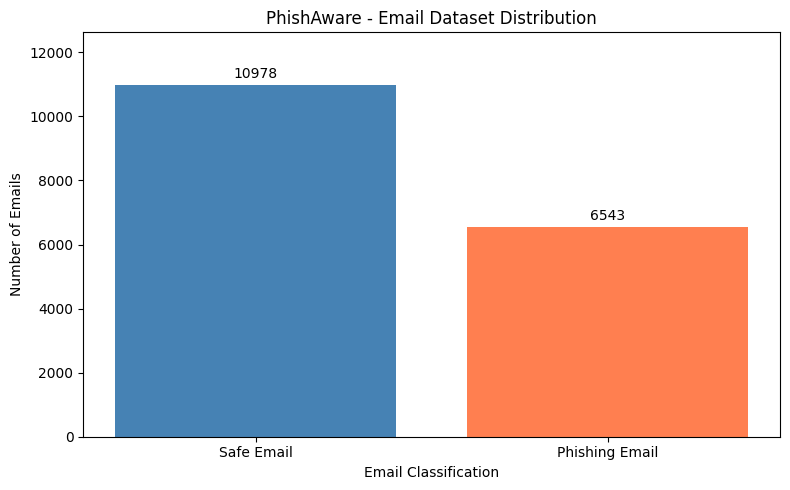

In [6]:
counts = df_clean["Email Type"].value_counts()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    counts.index,
    counts.values,
    color=["steelblue", "coral"]
)

plt.title("PhishAware - Email Dataset Distribution")
plt.xlabel("Email Classification")
plt.ylabel("Number of Emails")

plt.bar_label(bars, padding=3)
plt.ylim(0, counts.max() * 1.15)

plt.tight_layout()
plt.savefig("dataset_distribution.png", dpi=300)
plt.show()

In [7]:
X = df_clean["Email Text"]

y = df_clean["Email Type"].map({
    "Safe Email": 0,
    "Phishing Email": 1
})

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nClass distribution by split:")
print(pd.DataFrame({
    "Training": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Testing": y_test.value_counts()
}).rename(index={0: "Safe", 1: "Phishing"}))

print("\nDataset split completed successfully!")

Training samples: 12264
Validation samples: 2628
Testing samples: 2629

Class distribution by split:
            Training  Validation  Testing
Email Type                               
Safe            7684        1647     1647
Phishing        4580         981      982

Dataset split completed successfully!


In [8]:
vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

print("Total features:",
      len(vectorizer.get_feature_names_out()))

print("\nTF-IDF feature extraction successful!")

Training matrix: (12264, 5000)
Validation matrix: (2628, 5000)
Testing matrix: (2629, 5000)
Total features: 5000

TF-IDF feature extraction successful!


In [9]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1),

    "SVM": LinearSVC(random_state=42),

    "KNN": KNeighborsClassifier(
        n_neighbors=5, n_jobs=-1),

    "Naive Bayes": MultinomialNB(),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, random_state=42),

    "XGBoost": XGBClassifier(
        n_estimators=100, random_state=42,
        eval_metric="logloss", n_jobs=2),

    "LightGBM": LGBMClassifier(
        n_estimators=100, random_state=42,
        verbosity=-1, n_jobs=2),

    "CatBoost": CatBoostClassifier(
        iterations=100, random_seed=42,
        verbose=0, thread_count=2)
}

print("Total models:", len(models))

for i, name in enumerate(models, 1):
    print(f"{i}. {name}")

Total models: 10
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. SVM
5. KNN
6. Naive Bayes
7. Gradient Boosting
8. XGBoost
9. LightGBM
10. CatBoost


In [10]:
from sklearn.metrics import roc_auc_score, average_precision_score

results = []
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...", flush=True)

    start = time.time()

    model.fit(X_train_tfidf, y_train)

    training_time = time.time() - start

    predictions = model.predict(X_val_tfidf)

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_val_tfidf)[:, 1]
    else:
        scores = model.decision_function(X_val_tfidf)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, scores),
        "Average Precision": average_precision_score(y_val, scores),
        "False Positive Rate": fp / (fp + tn),
        "Training Time (s)": training_time
    })

    trained_models[name] = model

    print(f"{name} completed in {training_time:.2f} seconds.")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)

results_df.to_csv("validation_results.csv", index=False)

print("\nMODEL VALIDATION RESULTS")
display(results_df.round(4))

print("\nStrongest initial baseline:",
      results_df.iloc[0]["Model"])

Training Logistic Regression...
Logistic Regression completed in 0.39 seconds.
Training Decision Tree...
Decision Tree completed in 21.15 seconds.
Training Random Forest...
Random Forest completed in 13.32 seconds.
Training SVM...
SVM completed in 0.22 seconds.
Training KNN...
KNN completed in 0.01 seconds.
Training Naive Bayes...
Naive Bayes completed in 0.01 seconds.
Training Gradient Boosting...
Gradient Boosting completed in 65.72 seconds.
Training XGBoost...
XGBoost completed in 47.98 seconds.
Training LightGBM...
LightGBM completed in 27.05 seconds.
Training CatBoost...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


CatBoost completed in 87.67 seconds.

MODEL VALIDATION RESULTS


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,False Positive Rate,Training Time (s)
0,SVM,0.9768,0.9762,0.9613,0.9687,0.9967,0.9944,0.0140,0.2238
1,Logistic Regression,0.9737,0.9780,0.9511,0.9643,0.9966,0.9940,0.0128,0.3938
2,Random Forest,0.9680,0.9526,0.9623,0.9574,0.9950,0.9917,0.0285,13.3209
3,XGBoost,0.9673,0.9444,0.9694,0.9567,0.9951,0.9915,0.0340,47.9761
4,LightGBM,0.9669,0.9452,0.9674,0.9562,0.9956,0.9927,0.0334,27.0540
5,Naive Bayes,0.9631,0.9614,0.9388,0.9500,0.9931,0.9886,0.0225,0.0122
6,CatBoost,0.9604,0.9563,0.9368,0.9464,0.9939,0.9898,0.0255,87.6680
7,Gradient Boosting,0.9288,0.9471,0.8573,0.8999,0.9847,0.9730,0.0285,65.7177
8,Decision Tree,0.9197,0.8889,0.8970,0.8929,0.9181,0.8448,0.0668,21.1459
9,KNN,0.5689,0.4639,0.9959,0.6330,0.7793,0.5917,0.6855,0.0101



Strongest initial baseline: SVM


In [11]:
svm_tuning = []
best_svm = None
best_f1 = -1

for c in [0.01, 0.1, 0.5, 1, 2, 5, 10]:

    model = LinearSVC(
        C=c,
        random_state=42,
        max_iter=10000
    )

    model.fit(X_train_tfidf, y_train)

    pred = model.predict(X_val_tfidf)

    score = f1_score(y_val, pred)

    svm_tuning.append({
        "C": c,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1-score": score
    })

    if score > best_f1:
        best_f1 = score
        best_svm = model

tuning_df = pd.DataFrame(svm_tuning)

tuning_df = tuning_df.sort_values(
    "F1-score", ascending=False
)

display(tuning_df.round(4))

tuning_df.to_csv("svm_tuning_results.csv", index=False)

print("Best C value:", best_svm.C)
print("Best validation F1-score:", round(best_f1, 4))

,C,Accuracy,Precision,Recall,F1-score
2,0.50,0.9779,0.9772,0.9633,0.9702
3,1.00,0.9768,0.9762,0.9613,0.9687
1,0.10,0.9768,0.9802,0.9572,0.9685
4,2.00,0.9734,0.9710,0.9572,0.9641
5,5.00,0.9730,0.9681,0.9592,0.9636
6,10.00,0.9711,0.9651,0.9572,0.9611
0,0.01,0.9547,0.9865,0.8909,0.9363


Best C value: 0.5
Best validation F1-score: 0.9702


In [12]:
from sklearn.calibration import CalibratedClassifierCV

start = time.time()

calibrated_svm = CalibratedClassifierCV(
    LinearSVC(
        C=best_svm.C,
        random_state=42,
        max_iter=10000
    ),
    method="sigmoid",
    cv=3
)

calibrated_svm.fit(X_train_tfidf, y_train)

svm_prob = calibrated_svm.predict_proba(X_val_tfidf)[:, 1]

lr_prob = trained_models[
    "Logistic Regression"
].predict_proba(X_val_tfidf)[:, 1]

xgb_prob = trained_models[
    "XGBoost"
].predict_proba(X_val_tfidf)[:, 1]

hybrid_prob = (
    0.50 * svm_prob +
    0.30 * lr_prob +
    0.20 * xgb_prob
)

hybrid_pred = (hybrid_prob >= 0.5).astype(int)

print("PHISHAWARE PROPOSED HYBRID ALGORITHM")
print("-----------------------------------")
print("Accuracy:", round(accuracy_score(y_val, hybrid_pred), 4))
print("Precision:", round(precision_score(y_val, hybrid_pred), 4))
print("Recall:", round(recall_score(y_val, hybrid_pred), 4))
print("F1-score:", round(f1_score(y_val, hybrid_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, hybrid_prob), 4))

print("\nAdditional calibration and evaluation time:",
      round(time.time() - start, 4), "seconds")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, hybrid_pred))

PHISHAWARE PROPOSED HYBRID ALGORITHM
-----------------------------------
Accuracy: 0.9772
Precision: 0.9743
Recall: 0.9643
F1-score: 0.9693
ROC-AUC: 0.9976

Additional calibration and evaluation time: 1.17 seconds

Confusion Matrix:
[[1622   25]
 [  35  946]]


In [13]:
hybrid_results = []

for a in range(1, 9):
    for b in range(1, 10 - a):

        c = 10 - a - b

        weights = np.array([a, b, c]) / 10

        prob = (
            weights[0] * svm_prob +
            weights[1] * lr_prob +
            weights[2] * xgb_prob
        )

        for threshold in np.arange(0.30, 0.71, 0.05):

            pred = (prob >= threshold).astype(int)

            hybrid_results.append({
                "SVM Weight": weights[0],
                "LR Weight": weights[1],
                "XGB Weight": weights[2],
                "Threshold": threshold,
                "Accuracy": accuracy_score(y_val, pred),
                "Precision": precision_score(y_val, pred),
                "Recall": recall_score(y_val, pred),
                "F1-score": f1_score(y_val, pred)
            })

hybrid_tuning_df = pd.DataFrame(hybrid_results)

hybrid_tuning_df = hybrid_tuning_df.sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)

best_hybrid = hybrid_tuning_df.iloc[0]

print("Configurations tested:", len(hybrid_tuning_df))

print("\nTop 10 configurations:")
display(hybrid_tuning_df.head(10).round(4))

print("\nBest hybrid configuration:")
print(best_hybrid.round(4))

hybrid_tuning_df.to_csv(
    "hybrid_optimization.csv", index=False
)

Configurations tested: 324

Top 10 configurations:


,SVM Weight,LR Weight,XGB Weight,Threshold,Accuracy,Precision,Recall,F1-score
0,0.4,0.3,0.3,0.45,0.9787,0.9686,0.9745,0.9715
1,0.5,0.1,0.4,0.45,0.9783,0.9667,0.9755,0.9711
2,0.6,0.1,0.3,0.45,0.9783,0.9686,0.9735,0.9710
3,0.5,0.2,0.3,0.45,0.9783,0.9686,0.9735,0.9710
4,0.4,0.4,0.2,0.50,0.9783,0.9763,0.9653,0.9708
5,0.2,0.6,0.2,0.50,0.9779,0.9743,0.9664,0.9703
6,0.4,0.5,0.1,0.50,0.9779,0.9772,0.9633,0.9702
7,0.7,0.2,0.1,0.50,0.9779,0.9772,0.9633,0.9702
8,0.3,0.6,0.1,0.50,0.9779,0.9772,0.9633,0.9702
9,0.5,0.4,0.1,0.50,0.9779,0.9772,0.9633,0.9702



Best hybrid configuration:
SVM Weight    0.4000
LR Weight     0.3000
XGB Weight    0.3000
Threshold     0.4500
Accuracy      0.9787
Precision     0.9686
Recall        0.9745
F1-score      0.9715
Name: 0, dtype: float64


In [14]:
test_results = []
test_predictions = {}
test_scores = {}

def evaluate_test(name, pred, scores):

    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    test_predictions[name] = pred
    test_scores[name] = scores

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "Average Precision": average_precision_score(y_test, scores),
        "False Positive Rate": fp / (fp + tn),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

for name, model in trained_models.items():

    pred = model.predict(X_test_tfidf)

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test_tfidf)[:, 1]
    else:
        scores = model.decision_function(X_test_tfidf)

    evaluate_test(name, pred, scores)

evaluate_test(
    "Optimized SVM",
    best_svm.predict(X_test_tfidf),
    best_svm.decision_function(X_test_tfidf)
)

hybrid_test_prob = (
    best_hybrid["SVM Weight"] *
    calibrated_svm.predict_proba(X_test_tfidf)[:, 1]
    +
    best_hybrid["LR Weight"] *
    trained_models["Logistic Regression"].predict_proba(X_test_tfidf)[:, 1]
    +
    best_hybrid["XGB Weight"] *
    trained_models["XGBoost"].predict_proba(X_test_tfidf)[:, 1]
)

hybrid_test_pred = (
    hybrid_test_prob >= best_hybrid["Threshold"]
).astype(int)

evaluate_test(
    "PhishAware Hybrid",
    hybrid_test_pred,
    hybrid_test_prob
)

test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)

test_results_df.to_csv("final_test_results.csv", index=False)

print("FINAL TEST RESULTS")
display(test_results_df.round(4))

print("\nHighest test F1-score:",
      test_results_df.iloc[0]["Model"])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


FINAL TEST RESULTS


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,False Positive Rate,TN,FP,FN,TP
0,SVM,0.9821,0.9766,0.9756,0.9761,0.9972,0.9952,0.0140,1624,23,24,958
1,Optimized SVM,0.9814,0.9746,0.9756,0.9751,0.9974,0.9953,0.0152,1622,25,24,958
2,PhishAware Hybrid,0.9791,0.9668,0.9776,0.9722,0.9975,0.9953,0.0200,1614,33,22,960
3,Logistic Regression,0.9764,0.9752,0.9613,0.9682,0.9968,0.9941,0.0146,1623,24,38,944
4,LightGBM,0.9707,0.9520,0.9705,0.9612,0.9952,0.9912,0.0291,1599,48,29,953
5,Naive Bayes,0.9673,0.9619,0.9501,0.9559,0.9940,0.9887,0.0225,1610,37,49,933
6,Random Forest,0.9658,0.9451,0.9644,0.9546,0.9947,0.9908,0.0334,1592,55,35,947
7,XGBoost,0.9654,0.9433,0.9654,0.9542,0.9939,0.9885,0.0346,1590,57,34,948
8,CatBoost,0.9631,0.9548,0.9460,0.9504,0.9944,0.9902,0.0267,1603,44,53,929
9,Gradient Boosting,0.9312,0.9406,0.8707,0.9043,0.9851,0.9736,0.0328,1593,54,127,855



Highest test F1-score: SVM


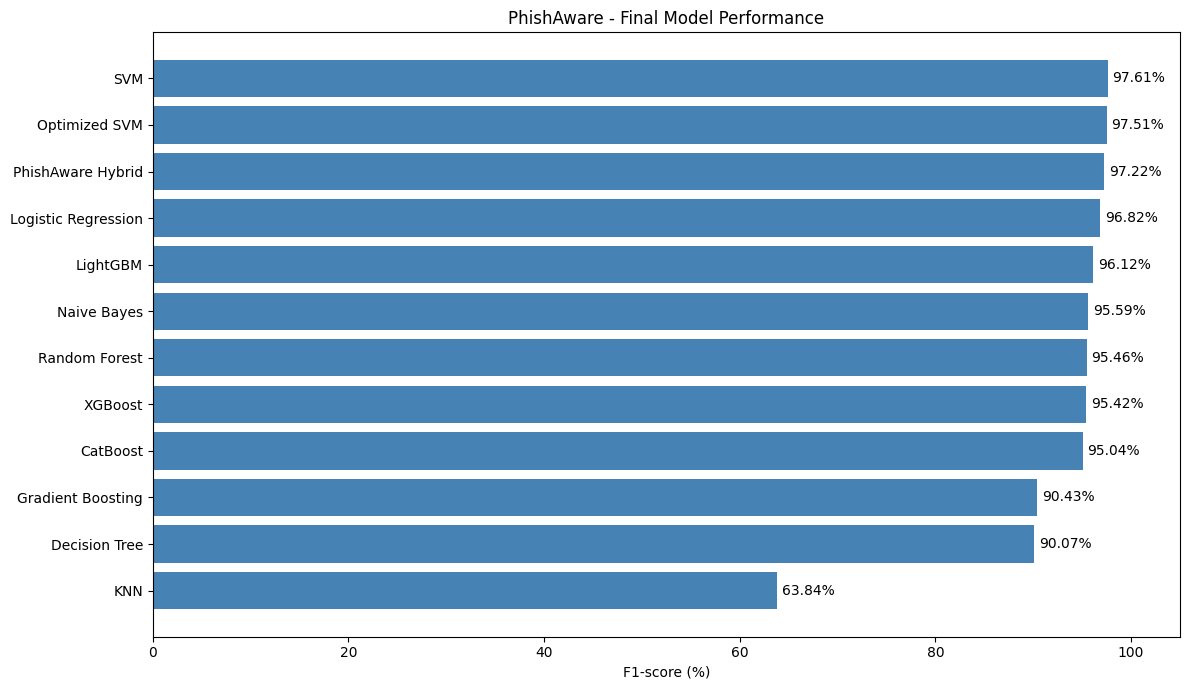

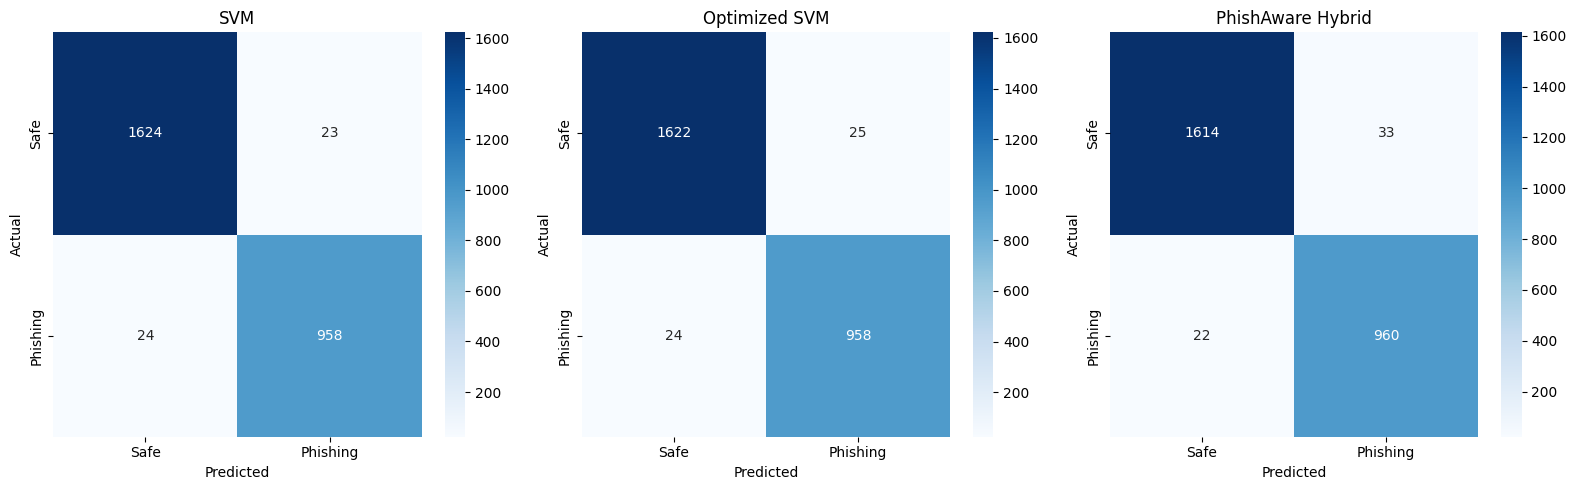

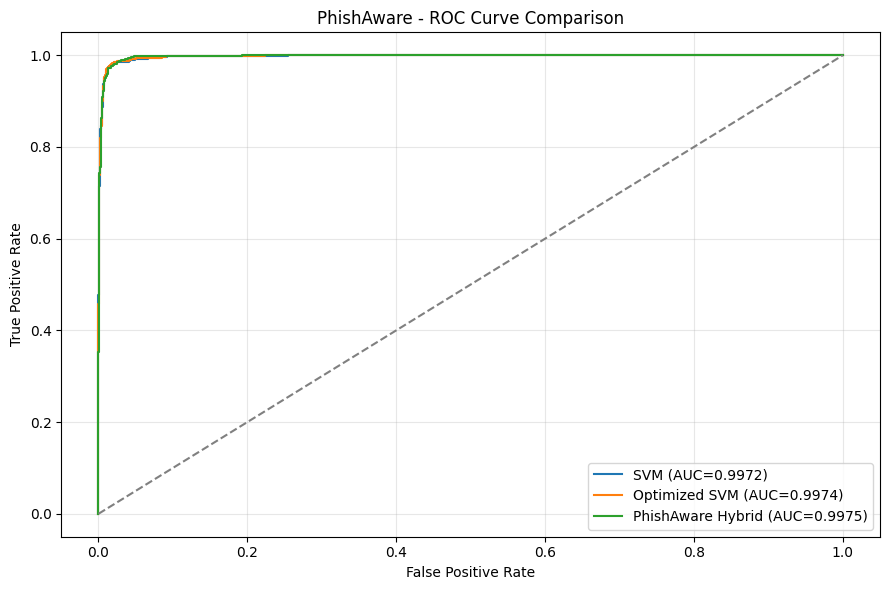

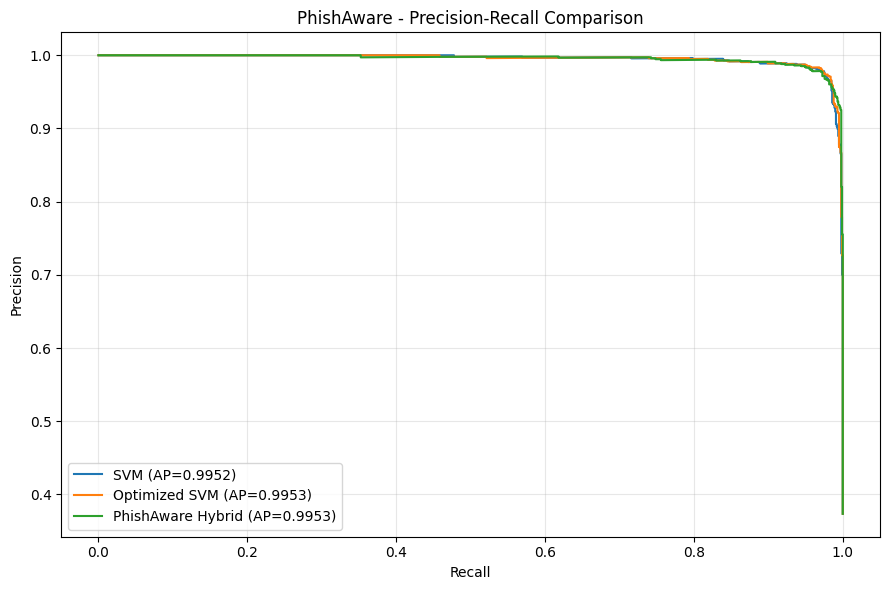

All four scientific charts generated successfully!


In [15]:
from sklearn.metrics import roc_curve, precision_recall_curve

# Chart 1: Model performance comparison
plt.figure(figsize=(12, 7))
plt.barh(
    test_results_df["Model"],
    test_results_df["F1-score"] * 100,
    color="steelblue"
)
plt.gca().invert_yaxis()
plt.xlabel("F1-score (%)")
plt.title("PhishAware - Final Model Performance")
plt.xlim(0, 105)

for i, value in enumerate(test_results_df["F1-score"]):
    plt.text(value * 100 + 0.5, i,
             f"{value * 100:.2f}%", va="center")

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()

# Chart 2: Confusion matrices
selected = ["SVM", "Optimized SVM", "PhishAware Hybrid"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, name in zip(axes, selected):
    cm = confusion_matrix(y_test, test_predictions[name])

    sns.heatmap(
        cm, annot=True, fmt="d",
        cmap="Blues", ax=ax,
        xticklabels=["Safe", "Phishing"],
        yticklabels=["Safe", "Phishing"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300)
plt.show()

# Chart 3: ROC curves
plt.figure(figsize=(9, 6))

for name in selected:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    auc = roc_auc_score(y_test, test_scores[name])

    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")

plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("PhishAware - ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=300)
plt.show()

# Chart 4: Precision-recall curves
plt.figure(figsize=(9, 6))

for name in selected:
    precision, recall, _ = precision_recall_curve(
        y_test, test_scores[name]
    )

    ap = average_precision_score(
        y_test, test_scores[name]
    )

    plt.plot(recall, precision,
             label=f"{name} (AP={ap:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PhishAware - Precision-Recall Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("precision_recall_curves.png", dpi=300)
plt.show()

print("All four scientific charts generated successfully!")

In [16]:
import os
import zipfile
from google.colab import files

test_results_df.to_csv("final_test_results.csv", index=False)
results_df.to_csv("validation_results.csv", index=False)

with zipfile.ZipFile(
    "PhishAware_Research_Results.zip", "w",
    zipfile.ZIP_DEFLATED
) as z:
    for filename in os.listdir("/content"):
        if filename.endswith((".png", ".csv")):
            if filename != "Phishing_Email.csv":
                z.write(
                    os.path.join("/content", filename),
                    filename
                )

files.download("PhishAware_Research_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>